# Analysis

## Setup

In [ ]:
#%pip install ax-platform botorch

In [ ]:
import numpy as np
from numpy import array
import os
from ax.api.client import Client
from ax.api.configs import RangeParameterConfig
from ax.generation_strategy.generation_strategy import GenerationStrategy
from ax.generation_strategy.generation_node import GenerationNode
from ax.generation_strategy.generator_spec import GeneratorSpec
from ax.adapter.registry import Generators
from botorch.acquisition.knowledge_gradient import qKnowledgeGradient
from botorch.acquisition.logei import qLogExpectedImprovement
from botorch.acquisition.monte_carlo import qUpperConfidenceBound
import logging
logging.getLogger("ax").setLevel(logging.WARNING)
import warnings
logging.disable(logging.INFO)          # blanket-silences INFO (and below) from every logger, everywhere
warnings.filterwarnings("ignore")       # silences warnings.warn() output too
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.stats import pearsonr
import torch
from botorch.test_functions import Branin, Levy, Ackley, Hartmann


## Data

In [ ]:
# load data
data = {}
for i in range(1, 9):
    function_name = f"function_{i}"
    folder_path = os.path.join("data/initial_data/", function_name)

    inputs = np.load(os.path.join(folder_path, "initial_inputs.npy"))
    outputs = np.load(os.path.join(folder_path, "initial_outputs.npy"))

    data[function_name] = {"inputs": inputs, "outputs": outputs}

# append new weekly data here
inputs = []
outputs = []
# new data 1
inputs.append([array([0.419272, 0.461948]), array([0.697723, 0.019697]), array([8.73804e-01, 3.27260e-02, 5.56000e-04]), array([0.425496, 0.40107 , 0.332   , 0.420664]), array([0.047984, 0.650324, 0.944067, 0.992311]), array([0.385184, 0.400217, 0.65163 , 0.631144, 0.438897]), array([0.445935, 0.576237, 0.512145, 0.574808, 0.575775, 0.431125]), array([0.084257, 0.105465, 0.030212, 0.078194, 0.960795, 0.361121, 0.255914, 0.26708 ])])
outputs.append([-0.003494886700825075, 0.6043746277406373, -0.20131519889874674, 0.28341867175066726, 1516.7842214139487, -0.5504788052903188, 0.3241500234866953, 9.9129406971235])
# new data 2
inputs.append([array([0.663323, 0.435684]), array([0.649791, 0.955219]), array([0.774714, 0.356627, 0.40228 ]), array([0.486709, 0.476973, 0.116256, 0.417109]), array([0.      , 0.      , 0.938555, 0.962415]), array([0.325154, 0.267231, 0.328883, 0.768068, 0.02488 ]), array([0.043071, 0.362635, 0.783296, 0.232831, 0.413318, 0.83637 ]), array([0.111041, 0.023895, 0.289   , 0.      , 0.685861, 0.665749, 0.264786, 0.      ])])
outputs.append([1.0264037214087058e-28, 0.4742130288797813, -0.023030335592178666, -7.1199862484002345, 940.2942145736226, -0.5954503716076427, 1.5282801802026906, 9.8071296833595])
# new data 3
inputs.append([array([0.618739, 0.220537]), array([0.835697, 0.999999]), array([0.      , 0.666061, 0.423285]), array([0.247025, 0.449997, 0.583954, 0.482487]), array([0.999999, 0.668162, 0.940547, 0.974566]), array([0.397699, 0.164007, 0.828967, 0.999999, 0.299491]), array([0.038343, 0.284404, 0.999999, 0.121377, 0.38399 , 0.695085]), array([0.207959, 0.04452 , 0.204792, 0.      , 0.876063, 0.107283, 0.129986, 0.999999])])
outputs.append([5.4240220487448864e-58, -0.05885334994798089, -0.0247551713482245, -5.1704598222077465, 4078.6874773136915, -0.8370661391600592, 0.9347303394535025, 9.7433588759804])
# new data 4
inputs.append([array([0.227536, 0.566017]), array([0.705807, 0.548955]), array([0.999999, 0.540497, 0.400658]), array([0.41542 , 0.383136, 0.403394, 0.425959]), array([0.999999, 0.767758, 0.999999, 0.999999]), array([0.469319, 0.386405, 0.637791, 0.692818, 0.155377]), array([0.20169 , 0.150011, 0.476874, 0.275332, 0.311652, 0.6573  ]), array([0.001972, 0.008806, 0.131631, 0.261367, 0.92781 , 0.578026, 0.201319, 0.999999])])
outputs.append([1.892322570267432e-42, 0.612831648853722, -0.022152998869090043, 0.5352182163010153, 5776.096706281166, -0.17705029514538193, 3.322368011391339, 9.9181755333759])
# new data 5
inputs.append([array([0.501 , 0.6073]), array([0.883078, 0.236094]), array([0.837649, 0.927754, 0.465419]), array([0.418584, 0.379256, 0.406197, 0.429294]), array([0.999999, 0.921966, 0.999999, 0.999999]), array([0.478768, 0.422867, 0.791407, 0.65817 , 0.094309]), array([0.107119, 0.063205, 0.453448, 0.406398, 0.324165, 0.719569]), array([0.152922, 0.169055, 0.165827, 0.183368, 0.999999, 0.507934, 0.269593, 0.862394])])
outputs.append([1.2116799057107965e-12, 0.359532625766316, -0.034779531489586096, 0.5517548820899845, 7368.460131627363, -0.40071660738163856, 2.584574932701675, 9.9524371048179])
# new data 6
inputs.append([array([0.221962, 0.223278]), array([0.715942, 0.922071]), array([0.999999, 0.604294, 0.475172]), array([0.419026, 0.379249, 0.406508, 0.430592]), array([0.999999, 0.999999, 0.999999, 0.999999]), array([0.446413, 0.456771, 0.529222, 0.678678, 0.177164]), array([0.264373, 0.126651, 0.43859 , 0.154992, 0.28695 , 0.793597]), array([0.177247, 0.      , 0.105174, 0.391505, 0.999999, 0.580597, 0.107939, 0.      ])])
outputs.append([1.0383814609232122e-57, 0.5285650618194462, -0.0010348652011470299, 0.536799367525433, 8662.405001248297, -0.3930424556731438, 2.4342873900004567, 9.8259460142775])
# new data 7
inputs.append([array([0.808622, 0.410889]), array([0.857852, 0.      ]), array([0.950484, 0.490519, 0.531522]), array([0.418501, 0.38018 , 0.40576 , 0.431613]), array([0.353261, 0.303126, 0.820002, 0.373798]), array([0.404148, 0.182392, 0.749577, 0.529626, 0.      ]), array([0.209681, 0.087109, 0.481524, 0.059147, 0.407955, 0.614856]), array([0.188806, 0.218388, 0.062127, 0.173278, 0.589641, 0.571855, 0.057843, 0.999999])])
outputs.append([-3.222233758935217e-56, 0.09718021442175606, -0.011576597835494739, 0.51005779755975, 0.5816128020529513, -0.5778770527323507, 2.005418917817736, 9.8814822317494])
# new data 8
inputs.append([array([0.546881, 0.546083]), array([0.678164, 0.999999]), array([0.470739, 0.611138, 0.458942]), array([0.417285, 0.381917, 0.404133, 0.432563]), array([0.702161, 0.794975, 0.837151, 0.999999]), array([0.411919, 0.48679 , 0.783364, 0.94022 , 0.      ]), array([0.337764, 0.665798, 0.542523, 0.305453, 0.325184, 0.665266]), array([0.      , 0.302408, 0.133092, 0.124992, 0.681179, 0.481294, 0.061693, 0.      ])])
outputs.append([8.595237675594048e-10, 0.4514871648643586, -0.009849881523881996, 0.4691478575606465, 1959.6530492003228, -0.5411562618430584, 1.2156775465259069, 9.8744509381255])
# new data 9
inputs.append([array([0.571917, 0.567835]), array([0.941419, 0.999999]), array([0.999999, 0.607276, 0.498188]), array([0.481045, 0.22124 , 0.380898, 0.507482]), array([0.999826, 0.288876, 0.779519, 0.519313]), array([0.423026, 0.62877 , 0.480473, 0.543956, 0.      ]), array([0.046445, 0.135532, 0.386253, 0.249827, 0.283312, 0.602237]), array([0.129074, 0.1863  , 0.14763 , 0.185138, 0.78337 , 0.494732, 0.229729, 0.780314])])
outputs.append([1.574363175484662e-05, -0.047678035219984406, -0.005387856411851771, -4.610188561426806, 673.1661801969509, -0.7273598714738623, 2.830570260706467, 9.9896396142884])
# new data 10
inputs.append([array([0.639566, 0.625206]), array([0.243426, 0.273512]), array([0.999999, 0.259149, 0.487006]), array([0.463321, 0.611678, 0.432794, 0.389708]), array([0.      , 0.416798, 0.999999, 0.999999]), array([0.550085, 0.48251 , 0.999999, 0.65934 , 0.20345 ]), array([0.199817, 0.      , 0.      , 0.263228, 0.367935, 0.645113]), array([0.017936, 0.329951, 0.149455, 0.      , 0.999999, 0.660958, 0.037136, 0.999999])])
outputs.append([1.4496686692120164, -0.15203143500348726, -0.03156142529464077, -4.232298862264802, 1687.1741726751177, -0.7973378619050021, 2.0836639487598574, 9.8155565835754])
# new data 11
inputs.append([array([0.6422, 0.6262]), array([0.6705  , 0.555934]), array([0.      , 0.668377, 0.520074]), array([0.183402, 0.46171 , 0.292681, 0.512619]), array([0.999999, 0.986284, 0.      , 0.999999]), array([0.571683, 0.191944, 0.462773, 0.783293, 0.      ]), array([0.205808, 0.      , 0.611847, 0.272581, 0.364133, 0.595803]), array([0.133571, 0.316731, 0.04815 , 0.      , 0.999999, 0.764653, 0.20745 , 0.      ])])
outputs.append([1.2511722461625223, 0.4403648663260973, -0.02806558605702874, -5.323204190736735, 4255.962712091933, -0.6437304352768639, 2.6974949521384235, 9.8011964666475])
# new data 12
inputs.append([array([0.645872, 0.612022]), array([0.69048 , 0.179175]), array([0.999999, 0.999999, 0.00526 ]), array([0.403305, 0.393584, 0.408291, 0.405387]), array([0.999999, 0.999999, 0.999999, 0.274356]), array([0.314378, 0.464949, 0.507565, 0.983826, 0.226501]), array([0.259532, 0.201152, 0.448851, 0.294944, 0.332911, 0.604932]), array([0.120704, 0.186952, 0.152578, 0.175095, 0.802231, 0.495161, 0.221075, 0.999999])])
outputs.append([0.48539262488487367, 0.5550863367386628, -0.1366592517615195, 0.37213864715425204, 4464.230863105729, -0.6399710871332811, 3.142616222523129, 9.9787040453354])


for week_inputs, week_outputs in zip(inputs, outputs):
    for i in range(8):
        function_name = f"function_{i+1}"

        data[function_name]["inputs"] = np.vstack([data[function_name]["inputs"], week_inputs[i]])
        data[function_name]["outputs"] = np.append(data[function_name]["outputs"], week_outputs[i])

for i in range(1, 9):
    function_name = f"function_{i}"
    print(f"{function_name} : max = {data[function_name]['outputs'].max():.6e}")

function_1 : max = 1.449669e+00
function_2 : max = 6.128316e-01
function_3 : max = -1.034865e-03
function_4 : max = 5.517549e-01
function_5 : max = 8.662405e+03
function_6 : max = -1.770503e-01
function_7 : max = 3.322368e+00
function_8 : max = 9.989640e+00


In [ ]:
# check
for function_name, arrays in data.items():
    inputs_shape = arrays["inputs"].shape
    outputs_shape = arrays["outputs"].shape
    print(f"{function_name} : inputs {inputs_shape}, outputs {outputs_shape}")

function_1 : inputs (21, 2), outputs (21,)
function_2 : inputs (21, 2), outputs (21,)
function_3 : inputs (26, 3), outputs (26,)
function_4 : inputs (41, 4), outputs (41,)
function_5 : inputs (31, 4), outputs (31,)
function_6 : inputs (31, 5), outputs (31,)
function_7 : inputs (41, 6), outputs (41,)
function_8 : inputs (51, 8), outputs (51,)


In [ ]:
# PRINT VALUES

def print_function_data(function_name):
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]
    param_names = [f"x{i+1}" for i in range(X.shape[1])]

    header = "  ".join(f"{p:>10s}" for p in param_names) + "   |   y"
    print(function_name)
    print(header)
    print("-" * len(header))

    for xi, yi in zip(X, y):
        row = "  ".join(f"{v:10.6f}" for v in xi)
        print(f"{row}   |   {yi:.6e}")
    print()


print_function_data("function_1")

function_1
        x1          x2   |   y
------------------------------
  0.319404    0.762959   |   1.322677e-79
  0.574329    0.879898   |   1.033078e-46
  0.731024    0.733000   |   7.710875e-16
  0.840353    0.264732   |   3.341771e-124
  0.650114    0.681526   |   -3.606063e-03
  0.410437    0.147554   |   -2.159249e-54
  0.312691    0.078723   |   -2.089093e-91
  0.683418    0.861057   |   2.535001e-40
  0.082507    0.403488   |   3.606771e-81
  0.883890    0.582254   |   6.229856e-48
  0.419272    0.461948   |   -3.494887e-03
  0.663323    0.435684   |   1.026404e-28
  0.618739    0.220537   |   5.424022e-58
  0.227536    0.566017   |   1.892323e-42
  0.501000    0.607300   |   1.211680e-12
  0.221962    0.223278   |   1.038381e-57



## GP models

In [ ]:
# KNOWLEDGE GRADIENT
process_functions_botorch = ["function_1", "function_2", "function_3", "function_4", "function_5", "function_6", "function_7", "function_8"]

recommendations_kg = {}
clients_kg = {}

default_num_fantasies = 256*2/4
default_num_restarts = 20*2/4
default_raw_samples = 2048*2/4

num_fantasies_multiplier = {f"function_{i+1}": 1 for i in range(8)}
num_restarts_multiplier = {f"function_{i+1}": 1 for i in range(8)}
raw_samples_multiplier = {f"function_{i+1}": 1 for i in range(8)}

num_fantasies_multiplier["function_3"] = num_restarts_multiplier["function_3"] = raw_samples_multiplier["function_3"] = 1#4
num_fantasies_multiplier["function_2"] = num_restarts_multiplier["function_2"] = raw_samples_multiplier["function_2"] = 1#4
num_fantasies_multiplier["function_8"] = num_restarts_multiplier["function_8"] = raw_samples_multiplier["function_8"] = 1#4
num_fantasies_multiplier["function_7"] = num_restarts_multiplier["function_7"] = raw_samples_multiplier["function_7"] = 1#4
num_fantasies_multiplier["function_5"] = num_restarts_multiplier["function_5"] = raw_samples_multiplier["function_5"] = 1#4

for function_name in process_functions_botorch:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    metric_name = "y"

    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    num_fantasies = int(default_num_fantasies * num_fantasies_multiplier[function_name])
    num_restarts = int(default_num_restarts * num_restarts_multiplier[function_name])
    raw_samples = int(default_raw_samples * raw_samples_multiplier[function_name])

    kg_node = GenerationNode(
        name="KG",
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs={
                    "botorch_acqf_class": qKnowledgeGradient,
                    "acquisition_options": {"num_fantasies": num_fantasies},
                },
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": num_restarts,
                            "raw_samples": raw_samples,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )

    client.set_generation_strategy(GenerationStrategy(name="KG-only", nodes=[kg_node]))

    for xi, yi in zip(X, y):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))
    next_x = np.array([next_params[p] for p in param_names])

    recommendations_kg[function_name] = next_x
    clients_kg[function_name] = client

    print(f"{function_name} : next point {next_x}")
    formatted_point = "-".join(f"{v:.6f}" for v in next_x)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point [0.67001473 0.615083  ]
function_1 : next point 0.670015-0.615083
function_2 : next point [0.7165383  0.10069212]
function_2 : next point 0.716538-0.100692
function_3 : next point [0.25239352 0.89727858 0.59916255]
function_3 : next point 0.252394-0.897279-0.599163
function_4 : next point [0.43111136 0.26402786 0.66999063 0.32435112]
function_4 : next point 0.431111-0.264028-0.669991-0.324351
function_5 : next point [0.         0.         0.         0.95370856]
function_5 : next point 0.000000-0.000000-0.000000-0.953709
function_6 : next point [0.29743111 0.49641186 0.47898385 1.         0.23979352]
function_6 : next point 0.297431-0.496412-0.478984-1.000000-0.239794
function_7 : next point [0.21420749 0.23695152 0.43226364 0.32753802 0.38900353 0.46384838]
function_7 : next point 0.214207-0.236952-0.432264-0.327538-0.389004-0.463848
function_8 : next point [0.08702961 0.40760008 0.         0.39681399 1.         0.34760302
 0.219047   1.        ]
function_8 : ne

In [ ]:
# EXPECTED IMPROVEMENT
process_functions_ei = ["function_1", "function_2", "function_3", "function_4",
                      "function_5", "function_6", "function_7", "function_8"]

recommendations_ei = {}
clients_ei = {}

for function_name in process_functions_ei:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    metric_name = "y"

    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    ei_node = GenerationNode(
        name="EI",
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs={
                    "botorch_acqf_class": qLogExpectedImprovement,
                },
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": 20,
                            "raw_samples": 1024,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )

    client.set_generation_strategy(GenerationStrategy(name="EI-only", nodes=[ei_node]))

    for xi, yi in zip(X, y):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))
    next_x = np.array([next_params[p] for p in param_names])

    recommendations_ei[function_name] = next_x
    clients_ei[function_name] = client

    print(f"{function_name} : next point {next_x}")
    formatted_point = "-".join(f"{v:.6f}" for v in next_x)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point [0.64587209 0.61202199]
function_1 : next point 0.645872-0.612022
function_2 : next point [0.69048006 0.17917531]
function_2 : next point 0.690480-0.179175
function_3 : next point [1.         1.         0.00525962]
function_3 : next point 1.000000-1.000000-0.005260
function_4 : next point [0.40330477 0.39358439 0.40829136 0.40538721]
function_4 : next point 0.403305-0.393584-0.408291-0.405387
function_5 : next point [1.         1.         1.         0.27435626]
function_5 : next point 1.000000-1.000000-1.000000-0.274356
function_6 : next point [0.31437764 0.46494904 0.5075652  0.983826   0.22650075]
function_6 : next point 0.314378-0.464949-0.507565-0.983826-0.226501
function_7 : next point [0.25953181 0.20115181 0.44885059 0.29494421 0.33291134 0.60493192]
function_7 : next point 0.259532-0.201152-0.448851-0.294944-0.332911-0.604932
function_8 : next point [0.12070382 0.18695231 0.15257813 0.17509523 0.80223129 0.49516105
 0.22107468 1.        ]
function_8 : ne

In [ ]:
# UPPER CONFIDENCE BOUND
process_functions_ucb = ["function_1", "function_2", "function_3", "function_4",
                      "function_5", "function_6", "function_7", "function_8"]

recommendations_ucb = {}
clients_ucb = {}

for function_name in process_functions_ucb:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    metric_name = "y"

    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    ucb_node = GenerationNode(
        name="UCB",
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs={
                    "botorch_acqf_class": qUpperConfidenceBound,
                    "acquisition_options": {"beta": 2.0},
                },
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": 20,
                            "raw_samples": 1024,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )

    client.set_generation_strategy(GenerationStrategy(name="UCB-only", nodes=[ucb_node]))

    for xi, yi in zip(X, y):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))
    next_x = np.array([next_params[p] for p in param_names])

    recommendations_ucb[function_name] = next_x
    clients_ucb[function_name] = client

    print(f"{function_name} : next point {next_x}")
    formatted_point = "-".join(f"{v:.6f}" for v in next_x)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point [0.6338514  0.62084544]
function_1 : next point 0.633851-0.620845
function_2 : next point [0.69123293 0.16463471]
function_2 : next point 0.691233-0.164635
function_3 : next point [1.         0.57780603 0.48795456]
function_3 : next point 1.000000-0.577806-0.487955
function_4 : next point [0.40755063 0.39699    0.40429077 0.41155556]
function_4 : next point 0.407551-0.396990-0.404291-0.411556
function_5 : next point [1. 1. 1. 1.]
function_5 : next point 1.000000-1.000000-1.000000-1.000000
function_6 : next point [0.42293333 0.38199572 0.60820249 0.74851461 0.15090841]
function_6 : next point 0.422933-0.381996-0.608202-0.748515-0.150908
function_7 : next point [0.247113   0.19000894 0.45477404 0.29251082 0.3281996  0.61962532]
function_7 : next point 0.247113-0.190009-0.454774-0.292511-0.328200-0.619625
function_8 : next point [0.1207045  0.18696068 0.15258014 0.17509963 0.80222945 0.49515616
 0.22107976 1.        ]
function_8 : next point 0.120704-0.186961-0.152

In [ ]:
# BATTLESHIP
process_functions_battleship = ["function_1"]#, "function_2", "function_3", "function_4",
                                 #"function_5", "function_6", "function_7", "function_8"]
recommendations_bs = {}
n_grid_points = 1_000_000
mean_weight = .3  # 0 = original pure-geometry behaviour; try e.g. 0.3

for function_name in process_functions_battleship:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]
    n_params = X.shape[1]

    # normalize known y values to [0, 1] : 0 = worst known, 1 = best known
    y_min, y_max = y.min(), y.max()
    if y_max > y_min:
        normalized_y = (y - y_min) / (y_max - y_min)
    else:
        normalized_y = np.full_like(y, 0.5)   # all points equal -> neutral weight

    # weight per point: 1-mean_weight at the bottom, 1 in the middle, 1+mean_weight at the top
    point_weights = 1 + mean_weight * (2 * normalized_y - 1)

    # random candidate grid, uniformly filling the [0, 1]^n_params domain
    candidates = np.random.uniform(0, 1, size=(n_grid_points, n_params))

    # for each candidate, distance to the nearest border (per dimension, then take the closest)
    border_distance = np.min(np.minimum(candidates, 1 - candidates), axis=1)

    # for each candidate, weighted distance to the nearest existing observation
    point_distance = np.full(n_grid_points, np.inf)
    for x_existing, weight in zip(X, point_weights):
        distance_to_this_point = np.linalg.norm(candidates - x_existing, axis=1) * weight
        point_distance = np.minimum(point_distance, distance_to_this_point)

    # "emptiest" = as far as possible from BOTH the border and any existing point
    emptiness_score = np.minimum(border_distance, point_distance)

    best_index = np.argmax(emptiness_score)
    next_point = candidates[best_index]

    recommendations_bs[function_name] = next_point

    formatted_point = "-".join(f"{v:.6f}" for v in next_point)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point 0.141934-0.858545


In [ ]:
# OVERVIEW OF ACQUISITION FUNCTIONS

methods = [
    ("KG", recommendations_kg, clients_kg),
    ("EI", recommendations_ei, clients_ei),
    ("UCB", recommendations_ucb, clients_ucb),
]

for function_name in recommendations_kg:
    print(function_name)

    for method_name, recommendations, clients in methods:
        if function_name not in recommendations:
            continue

        next_x = recommendations[function_name]
        client = clients[function_name]
        param_names = [f"x{i+1}" for i in range(len(next_x))]
        params = dict(zip(param_names, next_x.tolist()))

        prediction = client.predict([params])[0]
        mean, sigma = prediction["y"]

        print(f"  {method_name} : expected {mean:.4f} +/- {sigma:.4f}")

function_1
  KG : expected 1.1500 +/- 0.2136
  EI : expected 1.2325 +/- 0.1792
  UCB : expected 1.3367 +/- 0.0858
function_2
  KG : expected 0.4955 +/- 0.1248
  EI : expected 0.6173 +/- 0.0546
  UCB : expected 0.6191 +/- 0.0516
function_3
  KG : expected -0.0895 +/- 0.0164
  EI : expected -0.0479 +/- 0.0376
  UCB : expected -0.0028 +/- 0.0027
function_4
  KG : expected -6.0461 +/- 0.7226
  EI : expected -0.0970 +/- 0.2664
  UCB : expected -0.0901 +/- 0.2626
function_5
  KG : expected 637.9300 +/- 1085.7690
  EI : expected 7245.6564 +/- 648.1794
  UCB : expected 8449.9522 +/- 131.0226
function_6
  KG : expected -0.5526 +/- 0.1341
  EI : expected -0.4971 +/- 0.1160
  UCB : expected -0.2909 +/- 0.0361
function_7
  KG : expected 2.7768 +/- 0.3347
  EI : expected 3.2555 +/- 0.1611
  UCB : expected 3.2719 +/- 0.1396
function_8
  KG : expected 9.7548 +/- 0.0706
  EI : expected 9.9997 +/- 0.0161
  UCB : expected 9.9997 +/- 0.0161


## Plots

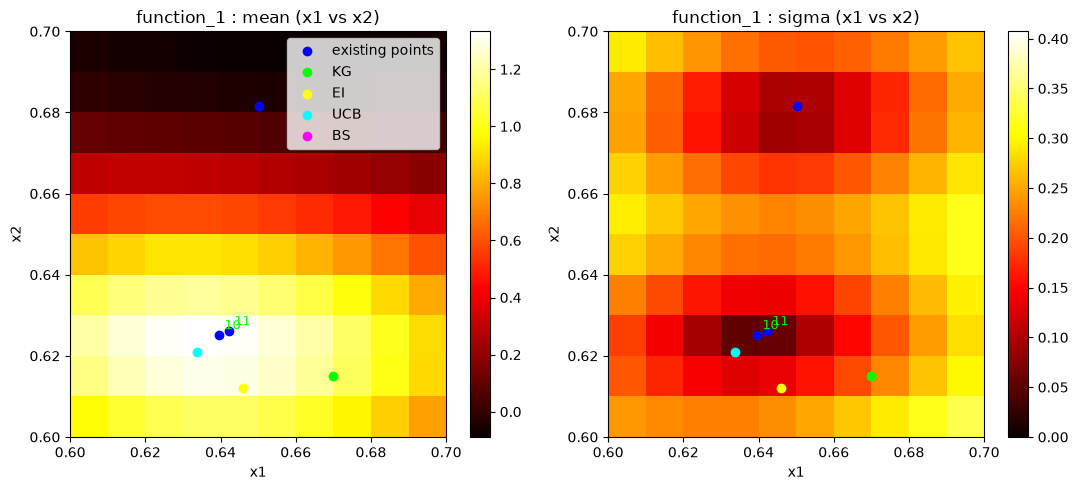

In [ ]:
# PLOT FUNCTIONS

plot_functions = ["function_1"]

initial_point_counts = {}

for i in range(1, 9):
    function_name = f"function_{i}"
    initial_inputs = np.load(f"data/initial_data/{function_name}/initial_inputs.npy")
    initial_point_counts[function_name] = initial_inputs.shape[0]

grid_size = 100
grid_values = np.linspace(0, 1, grid_size)
grid_a, grid_b = np.meshgrid(grid_values, grid_values)

recommendation_sets = [
    (recommendations_kg, "lime", "KG"),
    (recommendations_ei, "yellow", "EI"),
    (recommendations_ucb, "cyan", "UCB"),
    (recommendations_bs, "magenta", "BS"),
]

for function_name in plot_functions:
    client = clients_kg[function_name]
    X = data[function_name]["inputs"]
    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    n_params = len(param_names)
    n_initial = initial_point_counts[function_name]

    base_params = dict(zip(param_names, recommendations_kg[function_name].tolist()))

    for i in range(n_params - 1):
        param_a = param_names[i]
        param_b = param_names[i + 1]

        points = []
        for a, b in zip(grid_a.ravel(), grid_b.ravel()):
            params = dict(base_params)
            params[param_a] = a
            params[param_b] = b
            points.append(params)

        predictions = client.predict(points)
        mean = np.array([p["y"][0] for p in predictions]).reshape(grid_size, grid_size)
        sigma = np.array([p["y"][1] for p in predictions]).reshape(grid_size, grid_size)

        fig, axes = plt.subplots(1, 2, figsize=(11, 5))

        for ax, values, title in zip(axes, [mean, sigma], ["mean", "sigma"]):
            vmin = 0 if title == "sigma" else None
            im = ax.imshow(values, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="hot", vmin=vmin)
            ax.scatter(X[:, i], X[:, i + 1], color="blue", label="existing points")

            for j in range(n_initial, X.shape[0]):
                evolution_number = j - n_initial + 1
                ax.annotate(str(evolution_number), (X[j, i], X[j, i + 1]),
                            color="lime", textcoords="offset points", xytext=(4, 4), fontsize=9)

            for recommendations, color, label in recommendation_sets:
                if function_name in recommendations:
                    point = recommendations[function_name]
                    ax.scatter(point[i], point[i + 1], color=color, label=label)

            ax.set_xlabel(param_a)
            ax.set_ylabel(param_b)
            ax.set_title(f"{function_name} : {title} ({param_a} vs {param_b})")
            ax.set_xlim(.6,.7)
            ax.set_ylim(.6,.7)
            fig.colorbar(im, ax=ax)

        axes[0].legend()
        plt.tight_layout()
        plt.show()

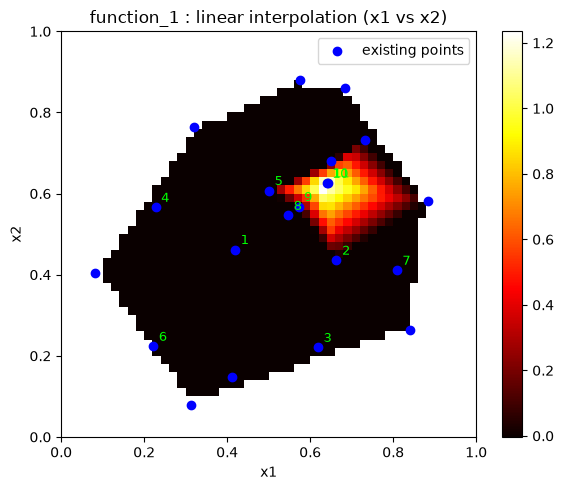

In [ ]:
# PLOT FUNCTIONS - LINEAR INTERPOLATION (model-free)
plot_functions_interp = ["function_1"]

grid_size = 50
grid_values = np.linspace(0, 1, grid_size)
grid_a, grid_b = np.meshgrid(grid_values, grid_values)

for function_name in plot_functions_interp:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]
    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    n_params = len(param_names)
    n_initial = initial_point_counts[function_name]

    for i in range(n_params - 1):
        param_a = param_names[i]
        param_b = param_names[i + 1]

        # linear interpolation using ONLY the two plotted dimensions and the raw y values
        # (other dimensions are ignored here, unlike the GP slice plots)
        interpolated = griddata(
            points=X[:, [i, i + 1]],
            values=y,
            xi=(grid_a, grid_b),
            method="linear",
        )

        fig, ax = plt.subplots(figsize=(6, 5))
        im = ax.imshow(interpolated, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="hot")
        ax.scatter(X[:, i], X[:, i + 1], color="blue", label="existing points")

        for j in range(n_initial, X.shape[0]):
            evolution_number = j - n_initial + 1
            ax.annotate(str(evolution_number), (X[j, i], X[j, i + 1]),
                        color="lime", textcoords="offset points", xytext=(4, 4), fontsize=9)

        ax.set_xlabel(param_a)
        ax.set_ylabel(param_b)
        ax.set_title(f"{function_name} : linear interpolation ({param_a} vs {param_b})")
        ax.legend()
        fig.colorbar(im, ax=ax)

        plt.tight_layout()
        plt.show()

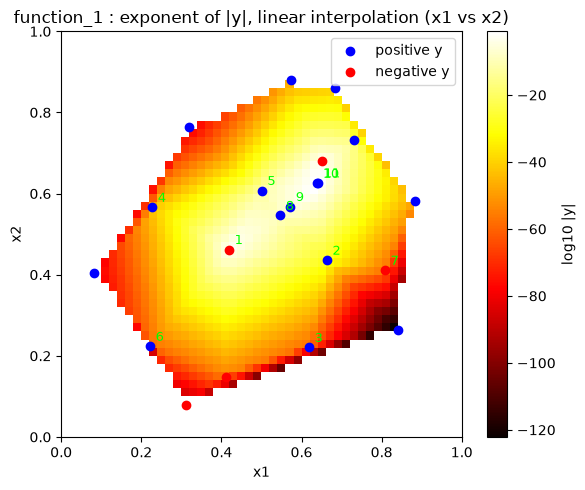

In [ ]:
# PLOT FUNCTIONS - LINEAR INTERPOLATION OF THE EXPONENT (model-free)
plot_functions_interp = ["function_1"]

grid_size = 50
grid_values = np.linspace(0, 1, grid_size)
grid_a, grid_b = np.meshgrid(grid_values, grid_values)

for function_name in plot_functions_interp:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]
    exponent = np.log10(np.abs(y))          # y = a * 10^x  ->  colour shows x
    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    n_params = len(param_names)
    n_initial = initial_point_counts[function_name]

    for i in range(n_params - 1):
        param_a = param_names[i]
        param_b = param_names[i + 1]

        # linear interpolation of the exponent using ONLY the two plotted dimensions
        interpolated = griddata(
            points=X[:, [i, i + 1]],
            values=exponent,
            xi=(grid_a, grid_b),
            method="linear",
        )

        fig, ax = plt.subplots(figsize=(6, 5))
        im = ax.imshow(interpolated, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="hot")

        # sign is lost in the exponent, so negative points are marked red
        positive = y > 0
        ax.scatter(X[positive, i], X[positive, i + 1], color="blue", label="positive y")
        ax.scatter(X[~positive, i], X[~positive, i + 1], color="red", label="negative y")

        for j in range(n_initial, X.shape[0]):
            evolution_number = j - n_initial + 1
            ax.annotate(str(evolution_number), (X[j, i], X[j, i + 1]),
                        color="lime", textcoords="offset points", xytext=(4, 4), fontsize=9)

        ax.set_xlabel(param_a)
        ax.set_ylabel(param_b)
        ax.set_title(f"{function_name} : exponent of |y|, linear interpolation ({param_a} vs {param_b})")
        ax.legend()
        cbar = fig.colorbar(im, ax=ax)
        cbar.set_label("log10 |y|")

        plt.tight_layout()
        plt.show()

## Benchmarking

In [ ]:
# CHECK IF FUNCTION 7 IS HARTMANN (Yes it is)

# Hartmann-6 definition (standard benchmark)
hartmann_alpha = np.array([1.0, 1.2, 3.0, 3.2])
hartmann_A = np.array([
    [10, 3, 17, 3.5, 1.7, 8],
    [0.05, 10, 17, 0.1, 8, 14],
    [3, 3.5, 1.7, 10, 17, 8],
    [17, 8, 0.05, 10, 0.1, 14],
])
hartmann_P = 1e-4 * np.array([
    [1312, 1696, 5569, 124, 8283, 5886],
    [2329, 4135, 8307, 3736, 1004, 9991],
    [2348, 1451, 3522, 2883, 3047, 6650],
    [4047, 8828, 8732, 5743, 1091, 381],
])

def hartmann6(x):
    inner = np.sum(hartmann_A * (x - hartmann_P) ** 2, axis=1)
    return np.sum(hartmann_alpha * np.exp(-inner))

X = data["function_7"]["inputs"]
y = data["function_7"]["outputs"]

y_hartmann = np.array([hartmann6(x) for x in X])

correlation, _ = pearsonr(y_hartmann, y)
residuals = y - y_hartmann

print(f"correlation : {correlation:.4f}")
print(f"max |residual| : {np.max(np.abs(residuals)):.4f}")
print()
print("observed y   vs   hartmann6(x)")
for yi, hi in zip(y, y_hartmann):
    print(f"{yi:10.4f}   {hi:10.4f}")

correlation : 1.0000
max |residual| : 0.0000

observed y   vs   hartmann6(x)
    0.6044       0.6044
    0.5628       0.5628
    0.0075       0.0075
    0.0614       0.0614
    0.2730       0.2730
    0.0837       0.0837
    1.3650       1.3650
    0.0926       0.0926
    0.0179       0.0179
    0.0336       0.0336
    0.0735       0.0735
    0.2063       0.2063
    0.0088       0.0088
    0.2684       0.2684
    0.6115       0.6115
    0.0148       0.0148
    0.2749       0.2749
    0.0668       0.0668
    0.0421       0.0421
    0.0027       0.0027
    0.0182       0.0182
    0.0070       0.0070
    0.1005       0.1005
    0.4754       0.4754
    0.6751       0.6751
    0.5165       0.5165
    0.0038       0.0038
    0.0031       0.0031
    0.0213       0.0213
    0.0954       0.0954
    0.3242       0.3242
    1.5283       1.5283
    0.9347       0.9347


In [ ]:
# COMPARE KG AGAINST EI FOR EACH ROUND

n_simulated_rounds = 50   # bump freely: every round now submits KG and shadow-checks EI

X_sim = data["function_7"]["inputs"].copy()
y_sim = data["function_7"]["outputs"].copy()

param_names = [f"x{i+1}" for i in range(X_sim.shape[1])]
metric_name = "y"

hartmann_optimum = 3.322368
x_opt = np.array([0.20169, 0.150011, 0.476874, 0.275332, 0.311652, 0.6573])


def make_client(node_name, acqf_class, acquisition_options):
    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    generator_kwargs = {"botorch_acqf_class": acqf_class}
    if acquisition_options:
        generator_kwargs["acquisition_options"] = acquisition_options

    node = GenerationNode(
        name=node_name,
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs=generator_kwargs,
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": 20,
                            "raw_samples": 2048,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )
    client.set_generation_strategy(GenerationStrategy(name=node_name, nodes=[node]))

    for xi, yi in zip(X_sim, y_sim):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))
    return np.array([next_params[p] for p in param_names])


for round_number in range(1, n_simulated_rounds + 1):

    # KG proposes and its point gets submitted (appended)
    next_x = make_client("KG", qKnowledgeGradient, {"num_fantasies": 256})
    next_y = hartmann6(next_x)

    # EI shadow: what would pure exploitation submit right now (evaluated, never appended)
    ei_x = make_client("EI-shadow", qLogExpectedImprovement, None)
    ei_y = hartmann6(ei_x)

    X_sim = np.vstack([X_sim, next_x])
    y_sim = np.append(y_sim, next_y)

    best_so_far = y_sim.max()
    dist = np.linalg.norm(next_x - x_opt)
    ei_dist = np.linalg.norm(ei_x - x_opt)

    print(f"round {round_number:2d} : KG y = {next_y:7.4f} (dist {dist:.3f}) | best = {best_so_far:7.4f} "
          f"| gap = {hartmann_optimum - best_so_far:7.4f} || EI-now: {ei_y:7.4f} (dist {ei_dist:.3f})")

round  1 : KG y =  0.1166 (dist 1.185) | best =  1.5283 | gap =  1.7941 || EI-now:  1.1955 (dist 0.498)
round  2 : KG y =  0.0465 (dist 0.885) | best =  1.5283 | gap =  1.7941 || EI-now:  1.1827 (dist 0.507)
round  3 : KG y =  0.0830 (dist 1.000) | best =  1.5283 | gap =  1.7941 || EI-now:  0.8072 (dist 0.673)
round  4 : KG y =  0.6626 (dist 0.648) | best =  1.5283 | gap =  1.7941 || EI-now:  1.4678 (dist 0.385)
round  5 : KG y =  1.2140 (dist 0.567) | best =  1.5283 | gap =  1.7941 || EI-now:  1.4982 (dist 0.433)
round  6 : KG y =  2.0086 (dist 0.310) | best =  2.0086 | gap =  1.3138 || EI-now:  1.4060 (dist 0.482)
round  7 : KG y =  2.0429 (dist 0.281) | best =  2.0429 | gap =  1.2795 || EI-now:  2.3570 (dist 0.252)
round  8 : KG y =  1.4761 (dist 0.318) | best =  2.0429 | gap =  1.2795 || EI-now:  2.3544 (dist 0.252)
round  9 : KG y =  1.3954 (dist 0.356) | best =  2.0429 | gap =  1.2795 || EI-now:  2.2543 (dist 0.273)
round 10 : KG y =  1.9729 (dist 0.393) | best =  2.0429 | gap = 

In [ ]:
# HELPER FUNCTION FOR BENCHMARKING

def make_client_sim(node_name, acqf_class, acquisition_options, X_cur, y_cur):
    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    generator_kwargs = {"botorch_acqf_class": acqf_class}
    if acquisition_options:
        generator_kwargs["acquisition_options"] = acquisition_options

    node = GenerationNode(
        name=node_name,
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs=generator_kwargs,
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": 20,
                            "raw_samples": 2048,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )
    client.set_generation_strategy(GenerationStrategy(name=node_name, nodes=[node]))

    for xi, yi in zip(X_cur, y_cur):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))

    # stash the client for optional prediction right after
    make_client_sim.last_client = client
    return np.array([next_params[p] for p in param_names])


def predict_mean_sim(X_cur, y_cur, x_query):
    client = make_client_sim.last_client       # reuse the fitted client from the shadow call
    params = dict(zip(param_names, x_query.tolist()))
    mean, sigma = client.predict([params])[0][metric_name]
    return mean

In [ ]:
# BENCHMARKING AGAINST HARTMANN ONLY (first benchmarking I did)

n_remaining_rounds = 10          # real rounds 4..13
k = 1                            # repeats per schedule (bump later)

# EI at these positions within the remaining rounds (1-based: 1 = round 4, 10 = round 13)
schedules = {
    "pure_KG_then_EI"  : [10],               # control: KG all the way, single final harvest
    "backloaded"       : [8, 9, 10],         # KG x7, then EI harvest streak
    "interleaved"      : [1, 6, 8, 10],      # my chip-in idea, roughly even
    "adaptive"         : "adaptive",         # EI when shadow-EI predicted mean > best + 10%
}

x_opt = np.array([0.20169, 0.150011, 0.476874, 0.275332, 0.311652, 0.6573])
results = {}

for schedule_name, ei_rounds in schedules.items():
    results[schedule_name] = []

    for repeat in range(k):
        torch.manual_seed(repeat)        # same seed per repeat index across schedules
        np.random.seed(repeat)

        X_sim = data["function_7"]["inputs"].copy()
        y_sim = data["function_7"]["outputs"].copy()
        submitted = []

        for round_number in range(1, n_remaining_rounds + 1):

            # decide method this round
            if ei_rounds == "adaptive":
                if round_number == n_remaining_rounds:
                    use_ei = True                     # last round always EI
                else:
                    # shadow EI: check if cashing in looks better than current best
                    ei_x = make_client_sim("EI-shadow", qLogExpectedImprovement, None, X_sim, y_sim)
                    ei_pred = predict_mean_sim(X_sim, y_sim, ei_x)
                    use_ei = ei_pred > y_sim.max() * 1.10
            else:
                use_ei = round_number in ei_rounds

            if use_ei:
                next_x = make_client_sim("EI", qLogExpectedImprovement, None, X_sim, y_sim)
                method = "EI"
            else:
                next_x = make_client_sim("KG", qKnowledgeGradient, {"num_fantasies": 256}, X_sim, y_sim)
                method = "KG"

            next_y = hartmann6(next_x)
            X_sim = np.vstack([X_sim, next_x])
            y_sim = np.append(y_sim, next_y)
            submitted.append(next_y)

        best_submitted = max(submitted)
        final_submitted = submitted[-1]
        results[schedule_name].append((best_submitted, final_submitted))
        print(f"{schedule_name:18s} repeat {repeat} : best submitted = {best_submitted:7.4f} "
              f"| final submitted = {final_submitted:7.4f}")

print()
for schedule_name, runs in results.items():
    bests = [b for b, f in runs]
    finals = [f for b, f in runs]
    print(f"{schedule_name:18s} : best = {np.mean(bests):7.4f} | final = {np.mean(finals):7.4f}")

pure_KG_then_EI    repeat 0 : best submitted =  1.6024 | final submitted =  0.4232
backloaded         repeat 0 : best submitted =  2.4937 | final submitted =  2.4937
interleaved        repeat 0 : best submitted =  1.6677 | final submitted =  1.6677
adaptive           repeat 0 : best submitted =  2.6695 | final submitted =  2.5501

pure_KG_then_EI    : best =  1.6024 | final =  0.4232
backloaded         : best =  2.4937 | final =  2.4937
interleaved        : best =  1.6677 | final =  1.6677
adaptive           : best =  2.6695 | final =  2.5501


In [ ]:
#
# BENCHMARKING 1 (CHECK AGAINST MULTIPLE FUNCTIONS)
#
k = 5
n_remaining_rounds = 10
KG_OPTIONS_BENCH = {"num_fantasies": 128}     # reduced for the benchmark study

# --- benchmark definitions: botorch function, initial points count (mimicking my real data sizes) ---
benchmark_definitions = {
    "Branin_2d":   {"fn": Branin(negate=True),        "n_initial": 12},
    "Levy_4d":     {"fn": Levy(dim=4, negate=True),   "n_initial": 30},
    "Hartmann_6d": {"fn": Hartmann(dim=6, negate=True), "n_initial": 30},
    "Ackley_8d":   {"fn": Ackley(dim=8, negate=True), "n_initial": 40},
}

schedules = {
    "pure_KG_then_EI": [10],
    "backloaded":      [8, 9, 10],
    "interleaved":     [3, 6, 8, 10],
    "adaptive":        "adaptive",
}


def make_oracle(botorch_fn):
    """Wrap a botorch test function into unit-cube coordinates."""
    lower = botorch_fn.bounds[0]
    upper = botorch_fn.bounds[1]

    def oracle(x_unit):
        x_scaled = lower + torch.tensor(x_unit, dtype=torch.double) * (upper - lower)
        return botorch_fn(x_scaled.unsqueeze(0)).item()

    return oracle


benchmark_results = {}

for benchmark_name, definition in benchmark_definitions.items():
    oracle = make_oracle(definition["fn"])
    dim = definition["fn"].dim
    n_initial = definition["n_initial"]

    # global names used inside make_client_sim
    param_names = [f"x{i+1}" for i in range(dim)]
    metric_name = "y"

    benchmark_results[benchmark_name] = {}

    for schedule_name, ei_rounds in schedules.items():
        benchmark_results[benchmark_name][schedule_name] = []

        for repeat in range(k):
            torch.manual_seed(repeat)
            np.random.seed(repeat)

            # same initial dataset for every schedule at this repeat (seeded before sampling)
            rng = np.random.default_rng(repeat)
            X_sim = rng.uniform(0, 1, size=(n_initial, dim))
            y_sim = np.array([oracle(x) for x in X_sim])

            submitted = []

            for round_number in range(1, n_remaining_rounds + 1):

                if ei_rounds == "adaptive":
                    if round_number == n_remaining_rounds:
                        use_ei = True
                    else:
                        ei_x = make_client_sim("EI-shadow", qLogExpectedImprovement, None, X_sim, y_sim)
                        ei_pred = predict_mean_sim(X_sim, y_sim, ei_x)
                        use_ei = ei_pred > y_sim.max() + 0.10 * abs(y_sim.max())
                else:
                    use_ei = round_number in ei_rounds

                if use_ei:
                    next_x = make_client_sim("EI", qLogExpectedImprovement, None, X_sim, y_sim)
                else:
                    next_x = make_client_sim("KG", qKnowledgeGradient, KG_OPTIONS_BENCH, X_sim, y_sim)

                next_y = oracle(next_x)
                X_sim = np.vstack([X_sim, next_x])
                y_sim = np.append(y_sim, next_y)
                submitted.append(next_y)

            initial_best = y_sim[:n_initial].max()
            best_submitted = max(submitted)
            benchmark_results[benchmark_name][schedule_name].append((best_submitted, submitted[-1], initial_best))

            print(f"{benchmark_name:12s} | {schedule_name:16s} | repeat {repeat} : "
                  f"initial best = {initial_best:9.4f} | best submitted = {best_submitted:9.4f} "
                  f"| final = {submitted[-1]:9.4f}")

# --- summary table ---
print()
print(f"{'benchmark':12s} | {'schedule':16s} | {'mean best':>10s} | {'mean final':>10s} | {'improvement':>11s}")
print("-" * 72)
for benchmark_name, by_schedule in benchmark_results.items():
    for schedule_name, runs in by_schedule.items():
        bests = np.mean([b for b, f, i in runs])
        finals = np.mean([f for b, f, i in runs])
        improvement = np.mean([b - i for b, f, i in runs])
        print(f"{benchmark_name:12s} | {schedule_name:16s} | {bests:10.4f} | {finals:10.4f} | {improvement:11.4f}")

Branin_2d    | pure_KG_then_EI  | repeat 0 : initial best =  -10.8692 | best submitted =   -2.0266 | final =   -2.0821
Branin_2d    | pure_KG_then_EI  | repeat 1 : initial best =   -3.6278 | best submitted =   -0.4085 | final =   -0.4085
Branin_2d    | pure_KG_then_EI  | repeat 2 : initial best =   -0.8426 | best submitted =   -1.9118 | final =   -6.6011
Branin_2d    | pure_KG_then_EI  | repeat 3 : initial best =   -5.0113 | best submitted =   -2.0470 | final =   -2.0470
Branin_2d    | pure_KG_then_EI  | repeat 4 : initial best =   -2.7390 | best submitted =   -1.0863 | final =   -1.0863
Branin_2d    | backloaded       | repeat 0 : initial best =  -10.8692 | best submitted =   -1.9986 | final =   -6.4422
Branin_2d    | backloaded       | repeat 1 : initial best =   -3.6278 | best submitted =   -0.4040 | final =  -10.1666
Branin_2d    | backloaded       | repeat 2 : initial best =   -0.8426 | best submitted =   -0.4807 | final =   -0.4807
Branin_2d    | backloaded       | repeat 3 : ini